# TD 2 — figures pour le tableau

Notebook de l'équipe, à projeter pendant la séance. Chaque figure accompagne un tableau du déroulé (`Deroule_TD2.pdf`) : le numéro est rappelé dans le titre (A = exercice 1, B = exercice 2, C = exercice 3).

**Les implémentations complètes (tirage discret, EM, PMC) sont dans `td2_outils.py`** : ce fichier ne doit pas être projeté ni distribué avant la date de rendu. Les cellules ci-dessous ne montrent que du code d'illustration (tracés, pièges numériques, méthode pour estimer une variance), jamais la réponse à une question du TD. Les exemples sont volontairement différents de ceux de l'énoncé.

Dépendances : `numpy`, `scipy`, `matplotlib`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from scipy.special import logsumexp
import td2_outils as T
from td2_outils import BLUE, ORANGE, GREEN, RED, GRAY, PURPLE, COLORS

T.style()
rng = np.random.default_rng(2026)

## Exercice 1 — lois discrètes

### A1. La fonction de répartition d'une loi discrète est un escalier
Cours 5 : $F^{-1}(u)=\inf\{x : F(x)\ge u\}$ et $X=F^{-1}(U)\sim F$. Ici, on regarde **le dessin** : où tombe $F^{-1}(u)$ pour quelques valeurs de $u$ ? Quelle est la longueur de l'intervalle des $u$ qui donnent $x_k$ ?

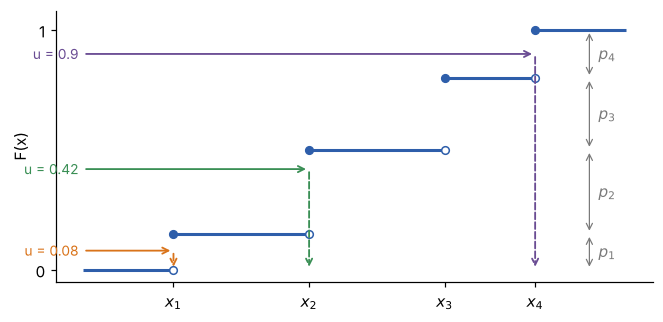

In [2]:
x = np.array([-1.0, 0.5, 2.0, 3.0])
p = np.array([0.15, 0.35, 0.3, 0.2])
F = np.cumsum(p)

fig, ax = plt.subplots(figsize=(7, 3.2))
xs = np.concatenate([[x[0] - 1], x, [x[-1] + 1]])
Fs = np.concatenate([[0], F, [1]])
for k in range(len(xs) - 1):
    ax.hlines(Fs[k], xs[k], xs[k + 1], color=BLUE, lw=2)
    if 0 < k:
        ax.plot(xs[k], Fs[k], "o", color=BLUE, ms=5)                 # point fermé (continuité à droite)
        ax.plot(xs[k], Fs[k - 1], "o", mfc="white", color=BLUE, ms=5)
for u, k, c in [(0.08, 0, ORANGE), (0.42, 1, GREEN), (0.9, 3, PURPLE)]:   # palier lu à la main sur le dessin
    ax.annotate("", xy=(x[k], u), xytext=(xs[0], u), arrowprops=dict(arrowstyle="->", color=c, lw=1.2))
    ax.annotate("", xy=(x[k], 0), xytext=(x[k], u), arrowprops=dict(arrowstyle="->", color=c, lw=1.2, ls="--"))
    ax.text(xs[0] - 0.05, u, f"u = {u}", color=c, ha="right", va="center", fontsize=9)
for k in range(len(x)):
    ax.annotate("", xy=(x[-1] + 0.6, F[k]), xytext=(x[-1] + 0.6, F[k] - p[k]),
                arrowprops=dict(arrowstyle="<->", color=GRAY, lw=0.8))
    ax.text(x[-1] + 0.7, F[k] - p[k] / 2, f"$p_{k+1}$", color=GRAY, va="center")
ax.set_xticks(x, [f"$x_{k+1}$" for k in range(len(x))]); ax.set_yticks([0, 1])
ax.set_ylim(-0.05, 1.08); ax.set_ylabel("F(x)")
plt.show()

### A2. Comparer les fréquences empiriques à la loi : quelle erreur attendre ?
La fréquence empirique $\hat p_k$ de $x_k$ sur $N$ tirages a pour écart-type $\sqrt{p_k(1-p_k)/N}$ (somme de Bernoulli). Les barres d'erreur à $\pm2$ écarts-types disent « à quel point l'histogramme doit coller ».

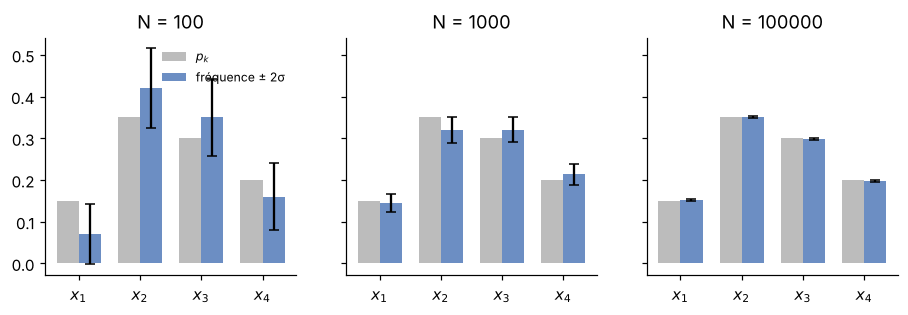

In [3]:
fig, axs = plt.subplots(1, 3, figsize=(10, 2.8), sharey=True)
for ax, N in zip(axs, [100, 1_000, 100_000]):
    X = T.sample_discrete(p, x, N, rng)                       # implémentation cachée dans td2_outils
    freq = np.array([np.mean(X == v) for v in x])
    err = 2 * np.sqrt(p * (1 - p) / N)
    pos = np.arange(len(x))
    ax.bar(pos - 0.18, p, 0.36, color=GRAY, alpha=0.5, label="$p_k$")
    ax.bar(pos + 0.18, freq, 0.36, color=BLUE, alpha=0.7, yerr=err, capsize=3, label="fréquence ± 2σ")
    ax.set_xticks(pos, [f"$x_{k+1}$" for k in pos]); ax.set_title(f"N = {N}")
axs[0].legend(fontsize=8); plt.show()

### A3. Piège numérique : la somme cumulée ne vaut pas toujours 1
Si `cdf[-1] < 1` et que `U` tombe au-dessus, l'indice sort du tableau (ou la dernière valeur n'est jamais tirée).

In [4]:
print("somme de dix 0.1 en float64 :", repr(np.cumsum([0.1] * 10)[-1]))
print("somme de dix 0.1 en float32 :", repr(np.cumsum(np.full(10, 0.1, np.float32))[-1]))
print("1 - (somme float64)          :", 1 - np.cumsum([0.1] * 10)[-1])

somme de dix 0.1 en float64 : np.float64(0.9999999999999999)
somme de dix 0.1 en float32 : np.float32(1.0000001)
1 - (somme float64)          : 1.1102230246251565e-16


### A4. Coût d'un tirage : balayage linéaire, dichotomie, alias (culture)
Balayage : $O(n)$ par tirage ; dichotomie (`np.searchsorted`) : $O(\log n)$ ; méthode d'alias (Walker, 1974) : $O(1)$ après une préparation en $O(n)$.

In [5]:
res = T.timing_discrete()
for r in res:
    print("  ".join(f"{k}={v*1e3:7.1f} ms" if k != "n" else f"n={v:6d}" for k, v in r.items()))

n=    10  lineaire=   11.2 ms  dichotomie=    6.0 ms  alias=    2.7 ms
n=   100  lineaire=   34.9 ms  dichotomie=   11.0 ms  alias=    2.9 ms
n=  1000  lineaire=  276.1 ms  dichotomie=   14.9 ms  alias=    2.8 ms
n= 10000  dichotomie=   20.2 ms  alias=    3.0 ms


## Exercice 2 — mélange gaussien et EM

### B1. Un mélange n'est pas une combinaison linéaire
$0.4\,\mathcal N(-1,1)+0.6\,\mathcal N(3,0.5^2)$ : on tire **d'abord** l'étiquette, **puis** la gaussienne correspondante. Le piège classique : calculer $0.4\,X_1+0.6\,X_2$, qui est une gaussienne (unimodale).

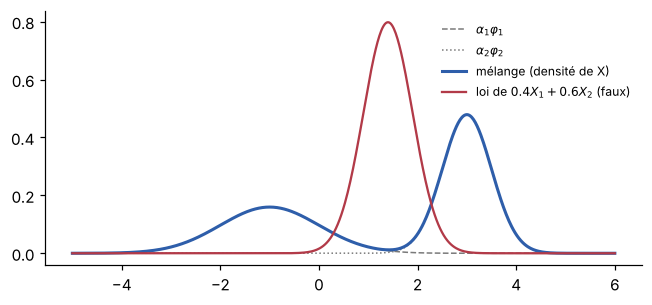

In [6]:
a, m1, s1, m2, s2 = 0.4, -1.0, 1.0, 3.0, 0.5
t = np.linspace(-5, 6, 600)
mix = a * stats.norm.pdf(t, m1, s1) + (1 - a) * stats.norm.pdf(t, m2, s2)
lin = stats.norm.pdf(t, a * m1 + (1 - a) * m2, np.sqrt(a**2 * s1**2 + (1 - a)**2 * s2**2))
fig, ax = plt.subplots()
ax.plot(t, a * stats.norm.pdf(t, m1, s1), "--", color=GRAY, lw=1, label=r"$\alpha_1\varphi_1$")
ax.plot(t, (1 - a) * stats.norm.pdf(t, m2, s2), ":", color=GRAY, lw=1, label=r"$\alpha_2\varphi_2$")
ax.plot(t, mix, color=BLUE, lw=2, label="mélange (densité de X)")
ax.plot(t, lin, color=RED, label=r"loi de $0.4X_1+0.6X_2$ (faux)")
ax.legend(fontsize=8); plt.show()

### B2. Le modèle génératif : ce qu'on simule, ce qu'on observe
À gauche, les données complètes $(X_i,Z_i)$ ; à droite, ce que voit le statisticien : les $X_i$ seuls. EM doit « retrouver les couleurs ».

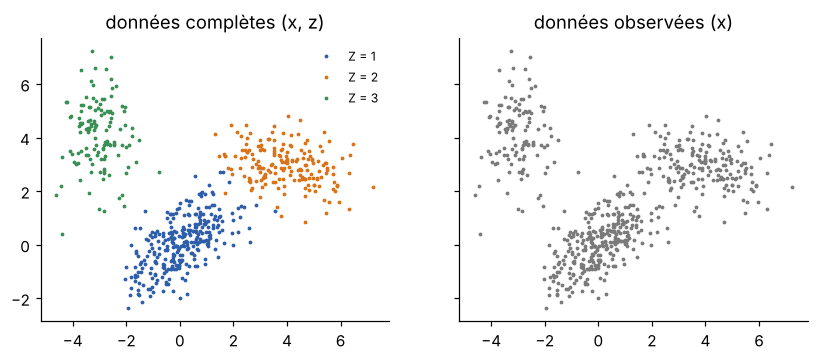

In [7]:
alphas = np.array([0.5, 0.3, 0.2])
mus = np.array([[0, 0], [4, 3], [-3, 4]], float)
Sigmas = np.array([[[1, .6], [.6, 1]], [[1.5, -.4], [-.4, .6]], [[.5, 0], [0, 1.5]]])
X2, z2 = T.gmm_sample(600, alphas, mus, Sigmas, rng)
fig, axs = plt.subplots(1, 2, figsize=(9, 3.8), sharex=True, sharey=True)
for j in range(3):
    axs[0].plot(*X2[z2 == j].T, ".", ms=3, color=COLORS[j], label=f"Z = {j+1}")
axs[1].plot(*X2.T, ".", ms=3, color=GRAY)
axs[0].set_title("données complètes (x, z)"); axs[1].set_title("données observées (x)")
axs[0].legend(fontsize=8)
for ax in axs: ax.set_aspect("equal")
plt.show()

### B3. Pourquoi pas de formule fermée : la log-vraisemblance en $(\mu_1,\mu_2)$
Mélange $\frac12\mathcal N(\mu_1,1)+\frac12\mathcal N(\mu_2,1)$ en dimension 1. La surface a **deux** maxima symétriques (échanger les étiquettes ne change pas la loi) et une crête entre les deux : pas de point critique unique, pas de formule fermée.

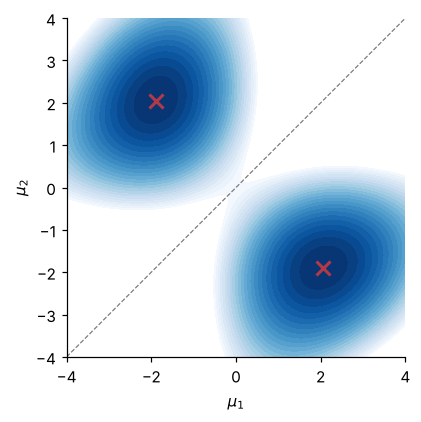

In [8]:
y1 = np.concatenate([rng.normal(-2, 1, 150), rng.normal(2, 1, 150)])
g = np.linspace(-4, 4, 161)
M1, M2 = np.meshgrid(g, g)
LL = np.array([[np.log(0.5 * stats.norm.pdf(y1, a_, 1) + 0.5 * stats.norm.pdf(y1, b_, 1)).sum() for a_ in g] for b_ in g])
fig, ax = plt.subplots(figsize=(4.6, 4))
cs = ax.contourf(M1, M2, LL, levels=np.linspace(LL.max() - 400, LL.max(), 25), cmap="Blues")
ax.plot([-4, 4], [-4, 4], color=GRAY, lw=0.8, ls="--")
i, j = np.unravel_index(LL.argmax(), LL.shape)
ax.plot([M1[i, j], M2[i, j]], [M2[i, j], M1[i, j]], "x", color=RED, ms=9, mew=2)
ax.set_xlabel(r"$\mu_1$"); ax.set_ylabel(r"$\mu_2$"); ax.set_aspect("equal"); plt.show()

### B4. Les responsabilités : « à quel point le point $x$ appartient-il à la classe $j$ ? »
$\tau_j(x)=\mathbb P(Z=j\mid X=x)=\dfrac{\alpha_j\varphi_j(x)}{\sum_k\alpha_k\varphi_k(x)}$ : formule de Bayes, rien d'autre. Elles valent presque 0 ou 1 loin de la frontière, et passent continûment de l'une à l'autre.

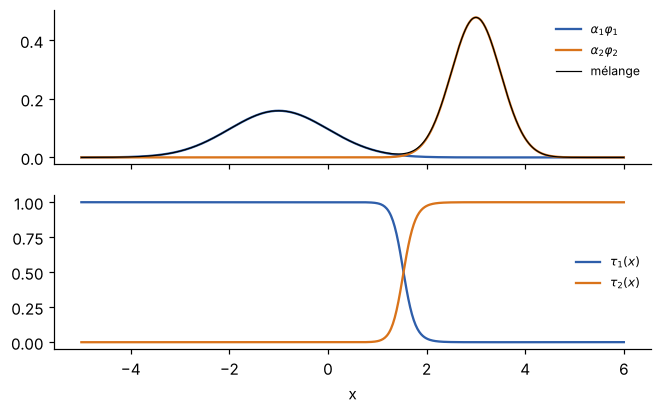

In [9]:
t = np.linspace(-5, 6, 600)
c1, c2 = a * stats.norm.pdf(t, m1, s1), (1 - a) * stats.norm.pdf(t, m2, s2)
fig, axs = plt.subplots(2, 1, figsize=(7, 4), sharex=True)
axs[0].plot(t, c1, color=BLUE, label=r"$\alpha_1\varphi_1$"); axs[0].plot(t, c2, color=ORANGE, label=r"$\alpha_2\varphi_2$")
axs[0].plot(t, c1 + c2, color="k", lw=0.8, label="mélange"); axs[0].legend(fontsize=8)
axs[1].plot(t, c1 / (c1 + c2), color=BLUE, label=r"$\tau_1(x)$"); axs[1].plot(t, c2 / (c1 + c2), color=ORANGE, label=r"$\tau_2(x)$")
axs[1].set_xlabel("x"); axs[1].legend(fontsize=8); plt.show()

### B5. EM maximise une minorante qui touche (cours 3)
Même dessin que dans le cours, calculé : $\ell(\theta)$ et $B(\theta,\theta_t)$ pour trois itérations. Seule $\mu_1$ est estimée.

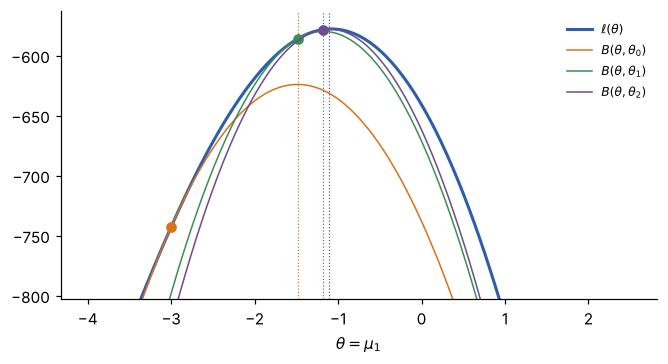

In [10]:
r2 = np.random.default_rng(7)
y = np.where(r2.random(300) < 0.5, r2.normal(-1.0, 1, 300), r2.normal(2.0, 1, 300))
grid = np.linspace(-4, 2.5, 600)
def ell(mu1):
    return np.log(0.5 * stats.norm.pdf(y[:, None], np.atleast_1d(mu1)[None, :], 1) + 0.5 * stats.norm.pdf(y[:, None], 2.0, 1)).sum(0)
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(grid, ell(grid), color=BLUE, lw=2, label=r"$\ell(\theta)$")
th = -3.0
for k, col in enumerate([ORANGE, GREEN, PURPLE]):
    f1, f2 = 0.5 * stats.norm.pdf(y, th, 1), 0.5 * stats.norm.pdf(y, 2.0, 1)
    r1 = f1 / (f1 + f2); r2_ = 1 - r1
    B = (r1[:, None] * (np.log(0.5 * stats.norm.pdf(y[:, None], grid, 1)) - np.log(r1[:, None]))
         + r2_[:, None] * (np.log(f2[:, None]) - np.log(r2_[:, None]))).sum(0)
    new = grid[np.argmax(B)]
    ax.plot(grid, B, color=col, lw=1, label=rf"$B(\theta,\theta_{k})$")
    ax.plot([th], ell(th), "o", color=col); ax.axvline(new, color=col, ls=":", lw=0.8)
    th = new
ax.set_ylim(ell(-3.0)[0] - 60, ell(grid).max() + 15); ax.set_xlabel(r"$\theta=\mu_1$"); ax.legend(fontsize=8); plt.show()

### B6. EM en action (dimension 2)
Ellipses à 2 écarts-types des composantes estimées, à plusieurs itérations, et la log-vraisemblance (qui ne doit **jamais** baisser).

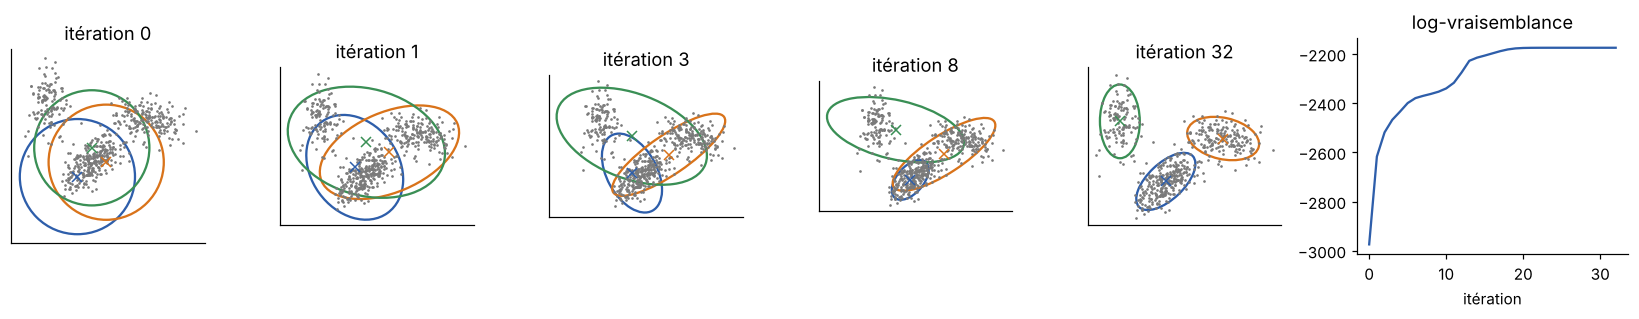

monotone : True   itérations : 33


In [11]:
init = (np.full(3, 1 / 3), np.array([[-1, -1], [1, 0], [0, 1]], float), np.array([np.eye(2) * 4] * 3))
(alh, muh, Sh), lls, hist = T.em_gmm(X2, 3, rng, init=init, n_iter=200, keep_history=True)
its = [0, 1, 3, 8, len(hist) - 1]
fig, axs = plt.subplots(1, len(its) + 1, figsize=(15, 3), gridspec_kw={"width_ratios": [1] * len(its) + [1.4]})
for ax, t in zip(axs, its):
    al, mu, S = hist[t]
    ax.plot(*X2.T, ".", ms=1.5, color=GRAY)
    for j in range(3):
        T.ellipse(ax, mu[j], S[j], COLORS[j], lw=1.5); ax.plot(*mu[j], "x", color=COLORS[j])
    ax.set_title(f"itération {t}"); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
axs[-1].plot(lls, color=BLUE); axs[-1].set_xlabel("itération"); axs[-1].set_title("log-vraisemblance")
plt.tight_layout(); plt.show()
print("monotone :", np.all(np.diff(lls) >= -1e-8), "  itérations :", len(lls))

### B7. Plusieurs initialisations : EM monte au premier sommet
Log-vraisemblance finale pour 20 initialisations aléatoires (sur des données à 4 groupes, $m=4$). Puis le plateau d'une initialisation symétrique (point selle).

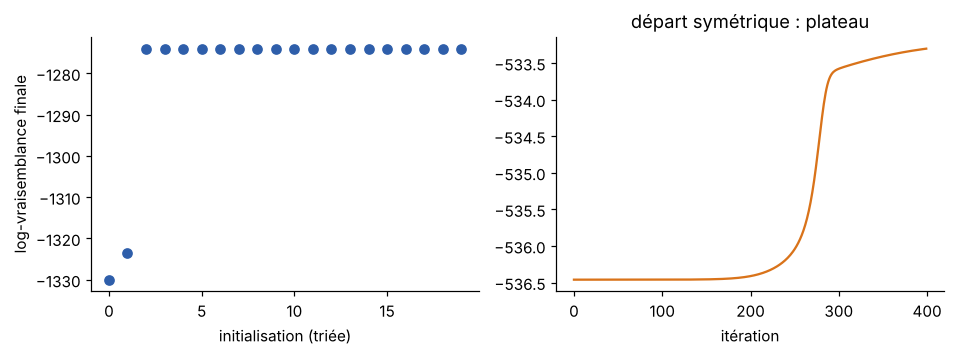

In [12]:
X4, _ = T.gmm_sample(400, np.full(4, .25), np.array([[0, 0], [3, 0], [0, 3], [3, 3]], float), np.array([np.eye(2) * .4] * 4), rng)
finals = []
for s in range(20):
    _, l, _ = T.em_gmm(X4, 4, np.random.default_rng(s), n_iter=500)
    finals.append(l[-1])
y3 = np.concatenate([rng.normal(0, 1, 150), rng.normal(2.0, 1, 150)])[:, None]
init_sym = (np.array([.5, .5]), np.array([[y3.mean() - 1e-3], [y3.mean() + 1e-3]]), np.array([[[y3.var()]]] * 2))
_, lsym, _ = T.em_gmm(y3, 2, rng, init=init_sym, n_iter=400, tol=0, reg=0)
fig, axs = plt.subplots(1, 2, figsize=(10, 3))
axs[0].plot(sorted(finals), "o", color=BLUE); axs[0].set_xlabel("initialisation (triée)"); axs[0].set_ylabel("log-vraisemblance finale")
axs[1].plot(lsym, color=ORANGE); axs[1].set_xlabel("itération"); axs[1].set_title("départ symétrique : plateau")
plt.show()

### B8. La vraisemblance n'est pas bornée
On centre une composante sur un point observé, $\mu_1=x_1$, et on fait tendre sa variance vers 0. La log-vraisemblance part à $+\infty$ : le maximum de vraisemblance n'existe pas, EM peut s'effondrer sur un point. (La preuve est à faire par les étudiants.)

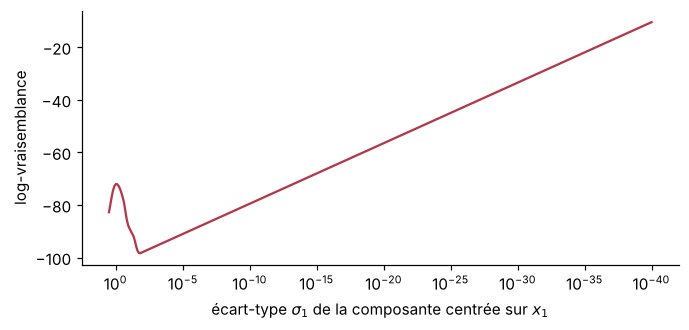

In [13]:
y4 = rng.normal(0, 1, 50)
sig = np.logspace(-40, 0.5, 400)
ll_deg = [np.log(0.5 * stats.norm.pdf(y4, y4[0], s) + 0.5 * stats.norm.pdf(y4, 0, 1)).sum() for s in sig]
plt.semilogx(sig, ll_deg, color=RED); plt.xlabel(r"écart-type $\sigma_1$ de la composante centrée sur $x_1$")
plt.ylabel("log-vraisemblance"); plt.gca().invert_xaxis(); plt.show()

### B9. Calculer en log : le « log-sum-exp »
En dimension 2 avec des points éloignés, $\varphi_j(x_i)$ vaut vite $10^{-300}$ : les responsabilités deviennent $0/0$. On calcule $\log(\alpha_j\varphi_j(x_i))$, puis on soustrait le maximum avant d'exponentier.

In [14]:
logs = np.array([-1000.0, -1001.0, -1003.0])        # log(alpha_j phi_j(x_i)) pour un point lointain
naif = np.exp(logs) / np.exp(logs).sum()
stable = np.exp(logs - logsumexp(logs))
print("naïf   :", naif)
print("stable :", stable.round(4))

naïf   : [nan nan nan]
stable : [0.7054 0.2595 0.0351]


/tmp/ipykernel_334/2696080592.py:2: RuntimeWarning: invalid value encountered in divide
  naif = np.exp(logs) / np.exp(logs).sum()


### B10. Choisir $m$ : la vraisemblance augmente toujours, le BIC non
Données simulées avec **3** groupes (pas les données ONU). Pour chaque $m$, meilleure de 10 initialisations. $-\log L$ décroît toujours ; la pénalité $\frac{\mathrm{df}(m)\log n}2$ croît linéairement.

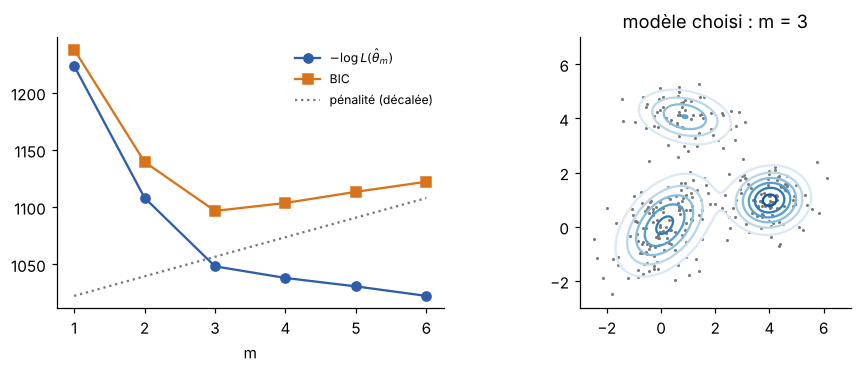

In [15]:
X3, _ = T.gmm_sample(300, np.array([.4, .35, .25]), np.array([[0, 0], [4, 1], [1, 4]], float),
                     np.array([[[1, .5], [.5, 1]], [[.6, 0], [0, .6]], [[1.2, -.3], [-.3, .5]]]), rng)
n, d = X3.shape
ms, nll, pen, best = range(1, 7), [], [], {}
for m in ms:
    runs = [T.em_gmm(X3, m, np.random.default_rng(s), n_iter=500) for s in range(10)]
    (par, l, _) = max(runs, key=lambda r: r[1][-1])
    best[m] = par; nll.append(-l[-1]); pen.append(T.n_params(m, d) * np.log(n) / 2)
nll, pen = np.array(nll), np.array(pen)
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
axs[0].plot(ms, nll, "o-", color=BLUE, label=r"$-\log L(\hat\theta_m)$")
axs[0].plot(ms, nll + pen, "s-", color=ORANGE, label="BIC")
axs[0].plot(ms, nll.min() + pen - pen[0], ":", color=GRAY, label="pénalité (décalée)")
axs[0].set_xlabel("m"); axs[0].legend(fontsize=8)
mb = ms[int(np.argmin(nll + pen))]
al, mu, S = best[mb]
gx, gy = np.meshgrid(np.linspace(-3, 7, 200), np.linspace(-3, 7, 200))
G = np.column_stack([gx.ravel(), gy.ravel()])
dens = np.exp(logsumexp(T.gmm_logcomp(G, al, mu, S), axis=1)).reshape(gx.shape)
axs[1].plot(*X3.T, ".", ms=2, color=GRAY); axs[1].contour(gx, gy, dens, levels=8, cmap="Blues")
axs[1].set_title(f"modèle choisi : m = {mb}"); axs[1].set_aspect("equal")
plt.show()

## Exercice 3 — échantillonnage préférentiel

Exemple jouet utilisé partout (différent de l'énoncé) : $p=\mathcal N(0,1)$, $g(x)=x^2$, donc $I=\mathbb E_p[g(X)]=1$ et $\mathrm{Var}_p(g)=2$.

### C1. Monte Carlo classique : erreur en $\sigma/\sqrt n$

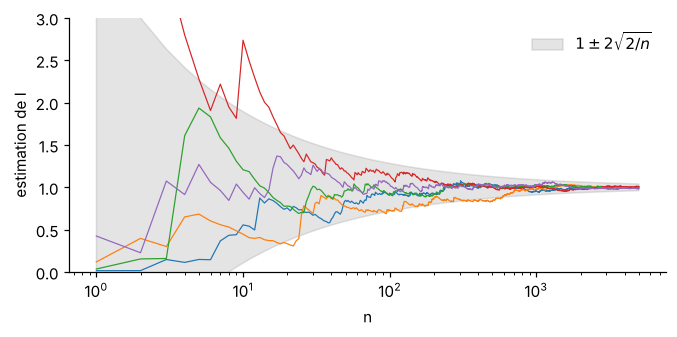

In [16]:
N = 5000
k = np.arange(1, N + 1)
fig, ax = plt.subplots()
for s in range(5):
    Xs = np.random.default_rng(s).standard_normal(N)
    ax.plot(k, np.cumsum(Xs**2) / k, lw=0.8)
ax.fill_between(k, 1 - 2 * np.sqrt(2 / k), 1 + 2 * np.sqrt(2 / k), color=GRAY, alpha=0.2, label=r"$1\pm2\sqrt{2/n}$")
ax.set_xscale("log"); ax.set_ylim(0, 3); ax.set_xlabel("n"); ax.set_ylabel("estimation de I"); ax.legend(); plt.show()

### C2. Ce que fait l'échantillonnage préférentiel
On tire sous $q$, on pondère par $w=p/q$. La densité qui annulerait la variance est $q^*\propto|g|\,p$ : elle met les points **là où $|g|p$ est grand**, pas là où $p$ est grand.

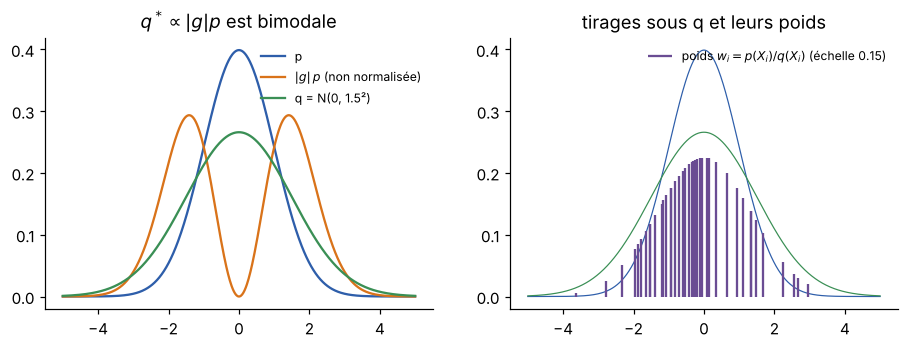

In [17]:
t = np.linspace(-5, 5, 600)
pt, gp = stats.norm.pdf(t), t**2 * stats.norm.pdf(t)
fig, axs = plt.subplots(1, 2, figsize=(10, 3.2))
axs[0].plot(t, pt, color=BLUE, label="p")
axs[0].plot(t, gp, color=ORANGE, label=r"$|g|\,p$ (non normalisée)")
axs[0].plot(t, stats.norm.pdf(t, 0, 1.5), color=GREEN, label=r"q = N(0, 1.5²)")
axs[0].legend(fontsize=8); axs[0].set_title(r"$q^* \propto |g|p$ est bimodale")
q = stats.norm(0, 1.5)
Xq = q.rvs(40, random_state=3)
w = stats.norm.pdf(Xq) / q.pdf(Xq)
axs[1].plot(t, pt, color=BLUE, lw=0.8); axs[1].plot(t, q.pdf(t), color=GREEN, lw=0.8)
axs[1].vlines(Xq, 0, w * 0.15, color=PURPLE, lw=1.5, label=r"poids $w_i=p(X_i)/q(X_i)$ (échelle 0.15)")
axs[1].legend(fontsize=8); axs[1].set_title("tirages sous q et leurs poids")
plt.show()

### C3. Bonne et mauvaise densité d'importance : les poids et l'ESS
$\mathrm{ESS}=\big(\sum w_i\big)^2/\sum w_i^2$ : vaut $n$ si tous les poids sont égaux, 1 si un seul domine.

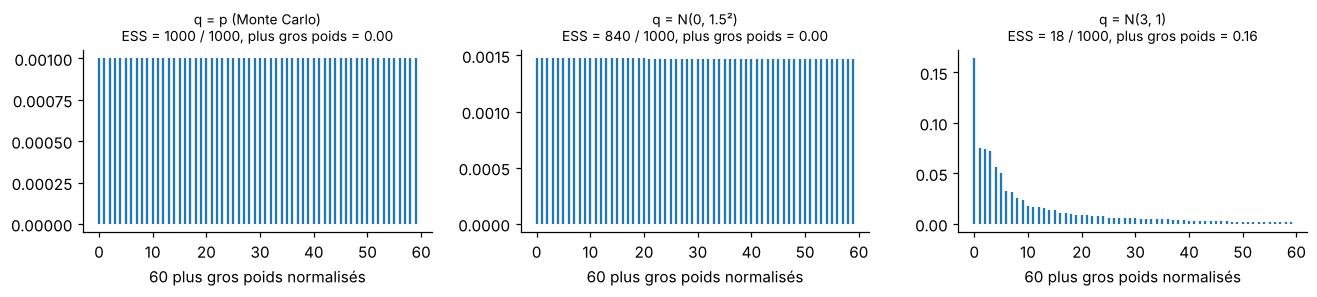

In [18]:
n = 1000
fig, axs = plt.subplots(1, 3, figsize=(12, 2.8), sharey=False)
for ax, (lab, qd) in zip(axs, [("q = p (Monte Carlo)", stats.norm(0, 1)), ("q = N(0, 1.5²)", stats.norm(0, 1.5)), ("q = N(3, 1)", stats.norm(3, 1))]):
    Xq = qd.rvs(n, random_state=1)
    w = stats.norm.pdf(Xq) / qd.pdf(Xq)
    wt = w / w.sum()
    ax.stem(np.sort(wt)[::-1][:60], markerfmt=" ", basefmt=" ")
    ax.set_title(f"{lab}\nESS = {T.ess(w):.0f} / {n}, plus gros poids = {wt.max():.2f}", fontsize=9)
    ax.set_xlabel("60 plus gros poids normalisés")
plt.tight_layout(); plt.show()

### C4. Des queues trop légères donnent une variance infinie
$p=\mathcal N(0,1)$, $q=\mathcal N(0,\sigma^2)$ : $\mathbb E_q[w^2]=\int p^2/q=\sigma^2/\sqrt{2\sigma^2-1}$, **infini si $\sigma^2\le1/2$**. La moyenne converge quand même (loi des grands nombres), mais par sauts : de rares points dans les queues portent des poids énormes.

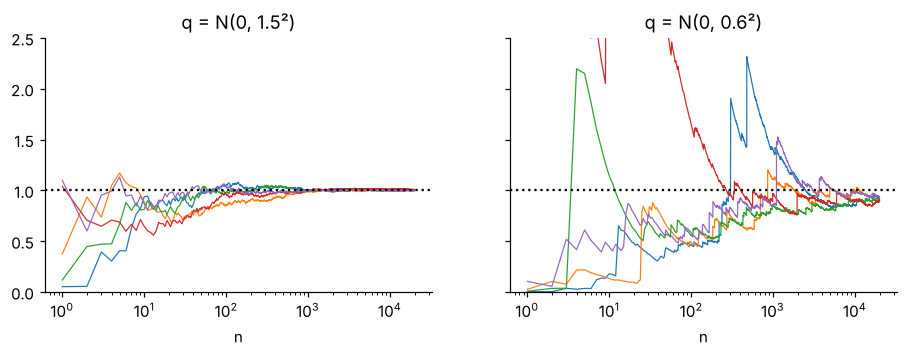

In [19]:
N = 20000
k = np.arange(1, N + 1)
fig, axs = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
for ax, sd in zip(axs, [1.5, 0.6]):
    for s in range(5):
        Xq = np.random.default_rng(s).normal(0, sd, N)
        w = stats.norm.pdf(Xq) / stats.norm.pdf(Xq, 0, sd)
        ax.plot(k, np.cumsum(w * Xq**2) / k, lw=0.8)
    ax.axhline(1, color="k", ls=":"); ax.set_xscale("log"); ax.set_title(f"q = N(0, {sd}²)"); ax.set_xlabel("n")
axs[0].set_ylim(0, 2.5); plt.show()

### C5. Estimer la moyenne et la variance d'un estimateur : on le relance
Un seul lancer donne **une** valeur. Pour estimer son biais et sa variance, on répète l'expérience $R$ fois, à $n$ fixé, puis on fait varier $n$. Si $n\times\mathrm{Var}$ est à peu près constant, on est dans le régime $1/\sqrt n$, et cette constante est l'**efficacité** de l'estimateur (plus petit = meilleur).

In [20]:
def is_estimate(n, qd, rng):
    Xq = qd.rvs(n, random_state=rng)
    w = stats.norm.pdf(Xq) / qd.pdf(Xq)
    return np.mean(w * Xq**2)

R = 500
for lab, qd in [("Monte Carlo (q = p)", stats.norm(0, 1)), ("q = N(0, 1.5²)", stats.norm(0, 1.5)), ("q = N(0, 0.8²)", stats.norm(0, 0.8))]:
    row = []
    for n in [10, 100, 1000]:
        est = np.array([is_estimate(n, qd, np.random.default_rng(r)) for r in range(R)])
        row.append(f"n={n:5d}: moy={est.mean():.3f} n·var={n * est.var():6.2f}")
    print(f"{lab:22s} | " + " | ".join(row))

Monte Carlo (q = p)    | n=   10: moy=0.984 n·var=  1.90 | n=  100: moy=0.990 n·var=  2.29 | n= 1000: moy=0.997 n·var=  1.88


q = N(0, 1.5²)         | n=   10: moy=1.012 n·var=  0.52 | n=  100: moy=0.995 n·var=  0.49 | n= 1000: moy=1.000 n·var=  0.49


q = N(0, 0.8²)         | n=   10: moy=0.919 n·var=  5.28 | n=  100: moy=0.991 n·var= 13.02 | n= 1000: moy=0.991 n·var= 11.43


### C6. Auto-normalisation : la constante disparaît, au prix d'un petit biais
Si l'on ne connaît que $\tilde p=c\,p$, on divise par $\sum_i w_i$. La constante $c$ s'élimine ; l'estimateur est un **rapport** de deux moyennes : biaisé à $n$ fini, convergent.

In [21]:
c = 7.3                                             # constante inconnue
R = 4000
for n in [5, 20, 100, 1000]:
    est_is, est_sn = [], []
    for r in range(R):
        Xq = np.random.default_rng(r).normal(0, 1.5, n)
        wt = c * stats.norm.pdf(Xq) / stats.norm.pdf(Xq, 0, 1.5)     # poids calculés avec p non normalisée
        est_is.append(np.mean(wt * Xq**2)); est_sn.append(np.sum(wt * Xq**2) / np.sum(wt))
    print(f"n={n:5d}  IS avec p~ : {np.mean(est_is):6.3f} (faux d'un facteur c)   auto-normalisé : moyenne {np.mean(est_sn):.4f}  (biais {np.mean(est_sn) - 1:+.4f})")

n=    5  IS avec p~ :  7.330 (faux d'un facteur c)   auto-normalisé : moyenne 1.1063  (biais +0.1063)


n=   20  IS avec p~ :  7.309 (faux d'un facteur c)   auto-normalisé : moyenne 1.0234  (biais +0.0234)


n=  100  IS avec p~ :  7.296 (faux d'un facteur c)   auto-normalisé : moyenne 1.0037  (biais +0.0037)


n= 1000  IS avec p~ :  7.301 (faux d'un facteur c)   auto-normalisé : moyenne 1.0006  (biais +0.0006)


### C7. Le sens du Kullback–Leibler compte
On approche une cible bimodale $\nu$ par **une** gaussienne. $\min_q K(\nu\|q)$ (le problème du TD) couvre toute la masse : c'est un maximum de vraisemblance sur des tirages de $\nu$. $\min_q K(q\|\nu)$ (inférence variationnelle, cours 1) choisit un mode.

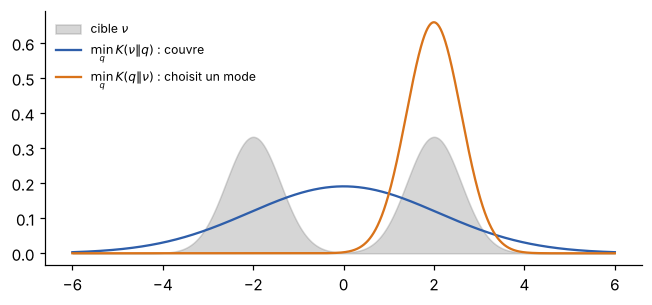

In [22]:
from scipy.optimize import minimize
t = np.linspace(-6, 6, 2001); dt = t[1] - t[0]
nu = 0.5 * stats.norm.pdf(t, -2, 0.6) + 0.5 * stats.norm.pdf(t, 2, 0.6)
m_cov, s_cov = (t * nu).sum() * dt, np.sqrt(((t - (t * nu).sum() * dt) ** 2 * nu).sum() * dt)   # min K(nu||q) : moments
def kl_q_nu(par):
    m, ls = par; q = stats.norm.pdf(t, m, np.exp(ls))
    return np.sum(q * (np.log(q + 1e-300) - np.log(nu + 1e-300))) * dt
r_ = minimize(kl_q_nu, [1.0, 0.0])
fig, ax = plt.subplots()
ax.fill_between(t, nu, color=GRAY, alpha=0.3, label=r"cible $\nu$")
ax.plot(t, stats.norm.pdf(t, m_cov, s_cov), color=BLUE, label=r"$\min_q K(\nu\|q)$ : couvre")
ax.plot(t, stats.norm.pdf(t, r_.x[0], np.exp(r_.x[1])), color=ORANGE, label=r"$\min_q K(q\|\nu)$ : choisit un mode")
ax.legend(fontsize=8); plt.show()

### C8. Population Monte Carlo sur une cible jouet (pas la banane)
Cible : mélange de deux gaussiennes allongées en dimension 2. Départ : $q^{(0)}$ large et mal placé. À chaque itération : tirer sous $q^{(t)}$, pondérer, ajuster $q^{(t+1)}$ (implémentation dans `td2_outils`). L'ESS remonte quand $q$ se rapproche de la cible.

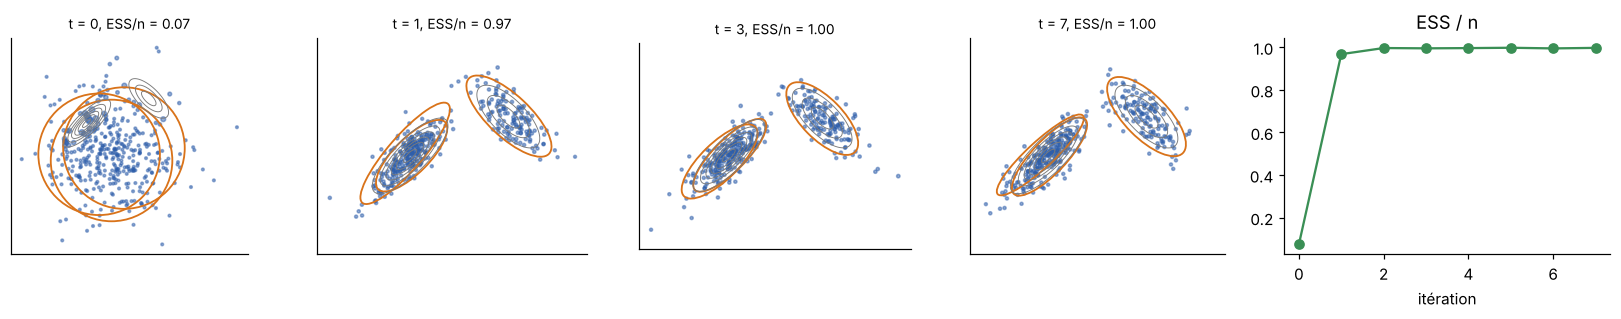

In [23]:
Sa = np.array([[1.0, 0.8], [0.8, 1.0]]); Sb = np.array([[1.0, -0.7], [-0.7, 1.0]])
def logtarget(X):
    return logsumexp(np.column_stack([np.log(.6) + T.log_gauss(X, np.array([-2., 0.]), Sa),
                                      np.log(.4) + T.log_gauss(X, np.array([3., 2.]), Sb)]), axis=1)
init = (np.full(3, 1 / 3), np.array([[0., -3.], [1., -2.], [-1., -2.5]]), np.array([np.eye(2) * 6] * 3))
out = T.pmc(logtarget, init, n=3000, n_iter=8, rng=np.random.default_rng(1))
gx, gy = np.meshgrid(np.linspace(-6, 7, 200), np.linspace(-5, 6, 200))
dens = np.exp(logtarget(np.column_stack([gx.ravel(), gy.ravel()]))).reshape(gx.shape)
show = [0, 1, 3, 7]
fig, axs = plt.subplots(1, len(show) + 1, figsize=(15, 3), gridspec_kw={"width_ratios": [1] * len(show) + [1.2]})
for ax, t_ in zip(axs, show):
    o = out[t_]
    ax.contour(gx, gy, dens, levels=6, colors=GRAY, linewidths=0.6)
    ax.scatter(*o["X"][:400].T, s=3 + 3000 * o["w"][:400], color=BLUE, alpha=0.5)
    for j in range(3):
        T.ellipse(ax, o["mus"][j], o["Sigmas"][j], ORANGE, lw=1.2)
    ax.set_title(f"t = {t_}, ESS/n = {o['ess'] / 3000:.2f}", fontsize=9); ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
axs[-1].plot([o["ess"] / 3000 for o in out], "o-", color=GREEN); axs[-1].set_xlabel("itération"); axs[-1].set_title("ESS / n")
plt.tight_layout(); plt.show()

### C9. La cible « banane » de l'énoncé (forme seulement)
Densité non normalisée, coupe dans $(x_1,x_2)$, les autres coordonnées à 0 (courbes de niveau de $\log\nu$). Utile pour vérifier visuellement les tirages pondérés.

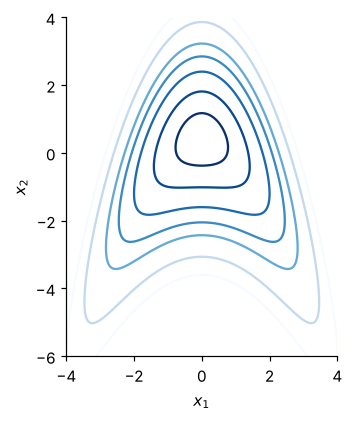

In [24]:
b, s1 = 0.4, 1.0
gx, gy = np.meshgrid(np.linspace(-4, 4, 300), np.linspace(-6, 4, 300))
lognu = -0.5 * (gx**2 / s1**2 + (gy + b * (gx**2 - s1**2)) ** 2)
fig, ax = plt.subplots(figsize=(4.5, 4))
ax.contour(gx, gy, lognu, levels=[-8, -6, -4, -3, -2, -1, -0.3], cmap="Blues"); ax.set_xlabel("$x_1$"); ax.set_ylabel("$x_2$"); ax.set_aspect("equal"); plt.show()

### C10. Poids en dimension 5 : travailler en log
$\log w_i=\log\tilde\nu(X_i)-\log q(X_i)$ peut valoir $-800$ : `np.exp` renvoie 0 pour tous les points. On soustrait le maximum avant d'exponentier (la normalisation fait disparaître la constante).

In [25]:
logw = np.array([-812.4, -805.1, -830.0, -806.7])
print("naïf   :", np.exp(logw) / np.exp(logw).sum())
w = np.exp(logw - logw.max()); w /= w.sum()
print("stable :", w.round(4), "  ESS =", round(1 / (w**2).sum(), 2))

naïf   : [nan nan nan nan]
stable : [6.000e-04 8.316e-01 0.000e+00 1.679e-01]   ESS = 1.39


/tmp/ipykernel_334/3671472753.py:2: RuntimeWarning: invalid value encountered in divide
  print("naïf   :", np.exp(logw) / np.exp(logw).sum())
